Generated Dataset
-------------------------------
 X	Y
1	15.48
2	15.31
3	22.24
4	29.62
5	23.83
6	26.83
7	38.90
8	37.84
9	34.65
10	42.71
11	40.68
12	43.67
13	50.21
14	42.43
15	46.38
16	55.19
17	55.94
18	65.57
19	62.46
20	62.94
21	80.33
22	74.87
23	79.34
24	74.88
25	82.28
26	88.55
27	85.25
28	95.88
29	94.00
30	98.54
31	99.99
32	115.26
33	108.93
34	106.71
35	119.11
36	111.90
37	122.04
38	114.20
39	120.36
40	130.98
41	136.69
42	136.86
43	138.42
44	140.49
45	137.61
46	144.40
47	148.70
48	159.29
49	158.72
50	151.18


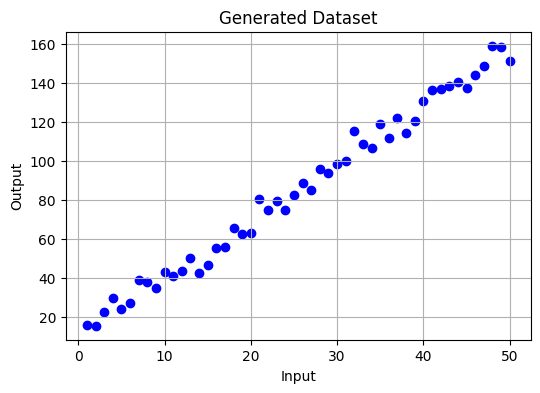

Epoch  10  Loss = 55.7677
Epoch  20  Loss = 42.0416
Epoch  30  Loss = 41.8169
Epoch  40  Loss = 41.6124
Epoch  50  Loss = 41.4100
Epoch  60  Loss = 41.2094
Epoch  70  Loss = 41.0108
Epoch  80  Loss = 40.8141
Epoch  90  Loss = 40.6193
Epoch 100  Loss = 40.4264


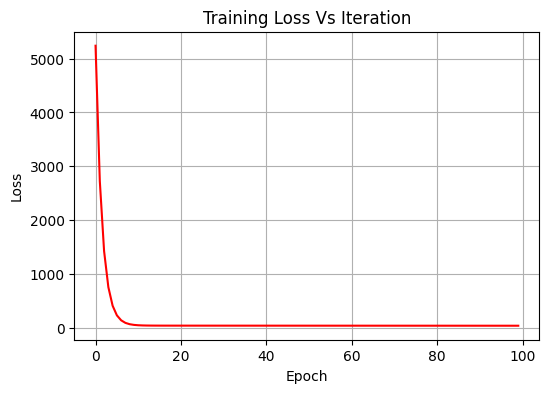

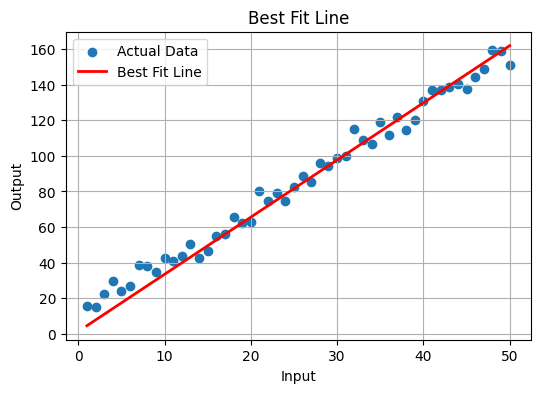


-------------------------------
New Sample Prediction
-------------------------------
Input : 60.0
Predicted Output : 193.8988037109375

Learned Weight : 3.2091197967529297
Learned Bias   : 1.3516194820404053


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# STEP 1 : Generate Dataset
# -------------------------------

np.random.seed(42)
torch.manual_seed(42)

x = np.arange(1, 51)
noise = np.random.randn(50) * 5
y = 3 * x + 10 + noise

# Convert to tensors
x_train = torch.tensor(x, dtype=torch.float32).view(-1, 1)
y_train = torch.tensor(y, dtype=torch.float32).view(-1, 1)

# -------------------------------
# Display Dataset
# -------------------------------

print("Generated Dataset")
print("-------------------------------")
print(" X\tY")

for i in range(len(x)):
    print(f"{x[i]}\t{y[i]:.2f}")

plt.figure(figsize=(6,4))
plt.scatter(x, y, color="blue")
plt.title("Generated Dataset")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.show()

# -------------------------------
# STEP 2 : Define Neural Network
# -------------------------------

class Model(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x):
        return self.linear(x)

# -------------------------------
# STEP 3 : Initialize Model
# -------------------------------

model = Model(1, 1)

criterion = nn.MSELoss()

optimizer = optim.SGD(model.parameters(), lr=0.001)

# -------------------------------
# STEP 4 : Train Model
# -------------------------------

epochs = 100

losses = []

for epoch in range(epochs):

    prediction = model(x_train)

    loss = criterion(prediction, y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}  Loss = {loss.item():.4f}")

# -------------------------------
# STEP 5 : Plot Loss Curve
# -------------------------------

plt.figure(figsize=(6,4))
plt.plot(losses, color="red")
plt.title("Training Loss Vs Iteration")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# -------------------------------
# STEP 6 : Best Fit Line
# -------------------------------

predicted = model(x_train).detach().numpy()

plt.figure(figsize=(6,4))
plt.scatter(x, y, label="Actual Data")
plt.plot(x, predicted, color="red", linewidth=2, label="Best Fit Line")
plt.title("Best Fit Line")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()

# -------------------------------
# STEP 7 : Predict New Sample
# -------------------------------

sample = torch.tensor([[60.0]])

prediction = model(sample)

print("\n-------------------------------")
print("New Sample Prediction")
print("-------------------------------")
print("Input :", sample.item())
print("Predicted Output :", prediction.item())

# -------------------------------
# Final Learned Parameters
# -------------------------------

print("\nLearned Weight :", model.linear.weight.item())
print("Learned Bias   :", model.linear.bias.item())